# 02 · Empirical data: error vs correct trials (response-locked ERN)

 **Validation on empirical results**: #EEGManyAnalysts Flanker dataset, channel FZ, response-locked epochs.
For every subject and condition (incorrect / correct) we compute four estimates of non-phase-locked power:

| Key | Pipeline |
|---|---|
| `induced_classic` | total power − power of the average ERP |
| `induced_woody` | same, after stochastic Woody alignment |
| `reg_classic` | single-trial regression of the average ERP, then power of the residuals → *poster: "ERP regressed out"* |
| `reg_woody` | stochastic Woody alignment → regression of the aligned ERP → reinstate original lags → power → *poster: "ERP regressed out + Woody filtering"* |


In [ ]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))  # make the repo's `ern_theta` package importable

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from tqdm import tqdm

from ern_theta import (align_trials, band_power, baseline_correct, compute_tfr,
                       regress_erp, reinstate_lags, woody_stochastic)
from ern_theta.config import (ERN_SUBJECTS, MIN_TRIALS, RESPONSE_CODES, RESULTS_DIR,
                              ern_epochs_file)
from ern_theta.io import load_single_channel

SEED = 42
FREQS = np.arange(1, 40, 0.25)
STOCH_WOODY_KW = dict(tol=0.1, max_it=100, n_runs=1000, max_lag_init=10,
                      xcorr_mthd='unbiased', max_shift=50)

## Per-subject analysis

In [ ]:
def analyze_subject(epochs_path, condition, rng):
    data, times, sfreq = load_single_channel(epochs_path, RESPONSE_CODES[condition])
    if len(data) < MIN_TRIALS:
        return None

    erp = data.mean(axis=0)

    # Stochastic Woody alignment
    _, lags, _ = woody_stochastic(data.T, rng=rng, **STOCH_WOODY_KW)
    aligned = align_trials(data, lags)
    erp_aligned = aligned.mean(axis=0)

    return {
        'n_trials': len(data),
        'times': times,
        'freqs': FREQS,
        'erp_raw': erp,
        'erp_woody': erp_aligned,
        # 1. Classic induced
        'tfr_total_classic': compute_tfr(data, FREQS, sfreq),
        'tfr_evoked_classic': compute_tfr(erp, FREQS, sfreq),
        # 2. Woody induced
        'tfr_total_woody': compute_tfr(aligned, FREQS, sfreq),
        'tfr_evoked_woody': compute_tfr(erp_aligned, FREQS, sfreq),
        # 3. Classic regression
        'tfr_reg_classic': compute_tfr(regress_erp(data, erp), FREQS, sfreq),
        # 4. Woody + regression + reinstated lags
        'tfr_reg_woody_reinstate': compute_tfr(
            reinstate_lags(regress_erp(aligned, erp_aligned), lags), FREQS, sfreq),
    }

In [ ]:
rng = np.random.default_rng(SEED)
results = {'incorrect': [], 'correct': []}

for sub_id in tqdm(ERN_SUBJECTS):
    sub_file = ern_epochs_file(sub_id)
    if not sub_file.exists():
        continue
    try:
        for condition in results:
            res = analyze_subject(sub_file, condition, rng)
            if res is not None:
                res['subject'] = sub_id
                results[condition].append(res)
    except Exception as e:
        print(f'Skipping {sub_id}: {e!r}')

results_incorrect, results_correct = results['incorrect'], results['correct']
print(f'Incorrect: {len(results_incorrect)}, Correct: {len(results_correct)}')

100%|██████████| 156/156 [4:45:35<00:00, 109.85s/it]   

Incorrect: 155, Correct: 156


## Group ERPs: raw vs Woody-aligned

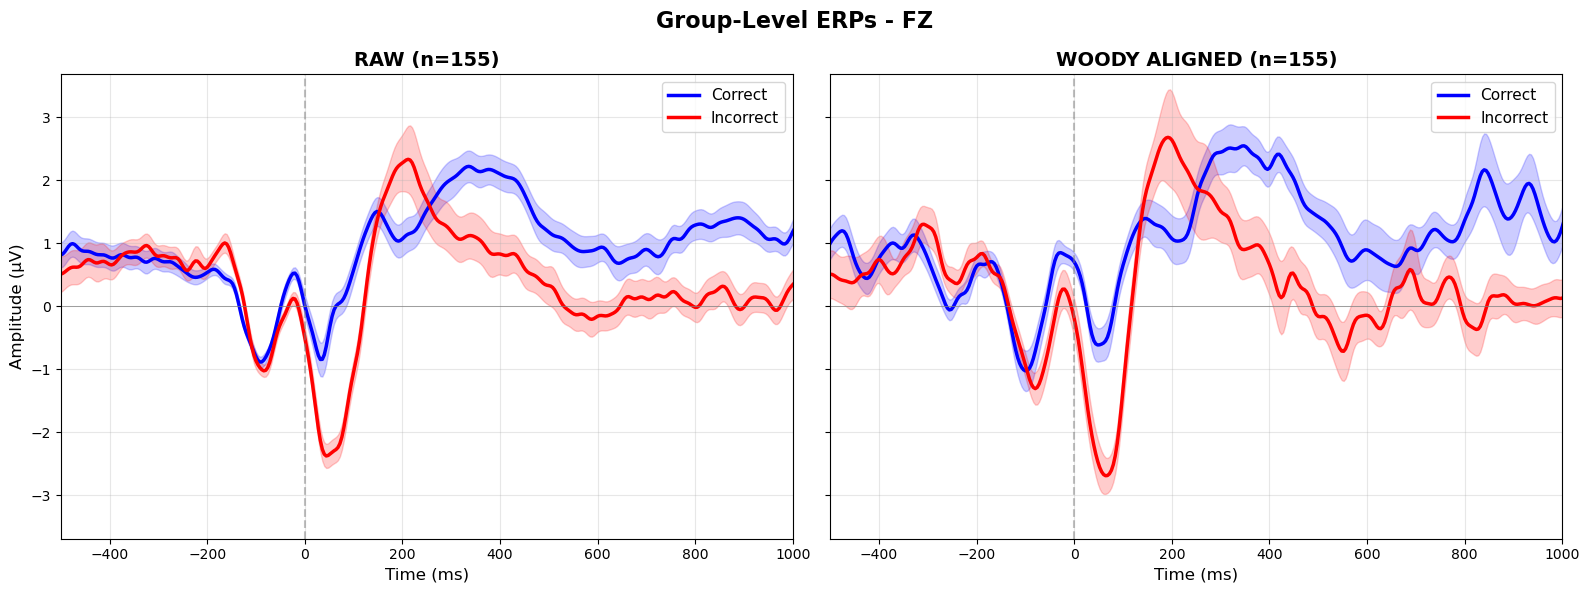

In [ ]:
times = results_incorrect[0]['times']


def mean_sem(results, key):
    x = np.array([r[key] for r in results])
    return x.mean(axis=0), x.std(axis=0) / np.sqrt(len(x))


erps = {(cond, key): mean_sem(res, key)
        for cond, res in [('Incorrect', results_incorrect), ('Correct', results_correct)]
        for key in ['erp_raw', 'erp_woody']}
all_means = np.concatenate([m for m, _ in erps.values()])

fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)
for ax, key, title in zip(axes, ['erp_raw', 'erp_woody'], ['RAW', 'WOODY ALIGNED']):
    for cond, color in [('Correct', 'b'), ('Incorrect', 'r')]:
        m, sem = erps[(cond, key)]
        ax.plot(times * 1000, m, color, linewidth=2.5, label=cond)
        ax.fill_between(times * 1000, m - sem, m + sem, color=color, alpha=0.2)
    ax.axvline(0, color='gray', linestyle='--', alpha=0.5)
    ax.axhline(0, color='gray', linewidth=0.5)
    ax.set_xlim(-500, 1000)
    ax.set_ylim(all_means.min() - 1, all_means.max() + 1)
    ax.set_xlabel('Time (ms)', fontsize=12)
    ax.set_title(f'{title} (n={len(results_incorrect)})', fontsize=14, fontweight='bold')
    ax.legend(fontsize=11)
    ax.grid(alpha=0.3)
axes[0].set_ylabel('Amplitude (µV)', fontsize=12)
plt.suptitle('Group-level ERPs - FZ', fontsize=16, fontweight='bold')
plt.tight_layout()

## Induced power and theta by pipeline

In [ ]:
METHODS = {
    'Induced Classic': ('black', lambda r: r['tfr_total_classic'] - r['tfr_evoked_classic']),
    'Induced Woody': ('dodgerblue', lambda r: r['tfr_total_woody'] - r['tfr_evoked_woody']),
    'Reg Classic': ('red', lambda r: r['tfr_reg_classic']),
    'Reg Woody+Reinstate': ('magenta', lambda r: r['tfr_reg_woody_reinstate']),
}


def corrected_tfr(r, method):
    return baseline_correct(METHODS[method][1](r), r['times'])


def theta_table(results):
    """Per-subject theta (4-8 Hz, 0-500 ms, % change) for every method."""
    return pd.DataFrame([
        {'subject': r['subject'],
         **{m: band_power(corrected_tfr(r, m), r['freqs'], r['times']) for m in METHODS}}
        for r in results
    ])


def plot_group_results(results, theta_df, title, methods=tuple(METHODS)):
    times, freqs, n = results[0]['times'], results[0]['freqs'], len(results)

    fig, axes = plt.subplots(1, len(methods), figsize=(5 * len(methods), 5),
                             sharex=True, sharey=True)
    for ax, method in zip(axes, methods):
        m = np.mean([corrected_tfr(r, method) for r in results], axis=0)
        im = ax.imshow(m, aspect='auto', origin='lower',
                       extent=[times[0] * 1000, times[-1] * 1000, freqs[0], freqs[-1]],
                       vmin=-100, vmax=100, cmap='RdBu_r')
        ax.axvline(0, color='k', ls='--', lw=2)
        ax.set_xlim(-500, 750)
        ax.set_ylim(3, 40)
        ax.set_title(method, fontweight='bold')
        ax.set_xlabel('Time (ms)')
    axes[0].set_ylabel('Frequency (Hz)')
    plt.tight_layout()
    fig.subplots_adjust(right=0.88)
    fig.colorbar(im, cax=fig.add_axes([0.90, 0.15, 0.02, 0.7]), label='% change')
    fig.suptitle(f'Induced power - {title} (n={n})', fontweight='bold', y=1.02)

    fig, ax = plt.subplots(figsize=(2 * len(methods) + 1, 5))
    ax.bar(range(len(methods)), theta_df[list(methods)].mean(),
           yerr=theta_df[list(methods)].sem(), color=[METHODS[m][0] for m in methods],
           alpha=0.7, edgecolor='k', lw=2, capsize=5)
    ax.set_xticks(range(len(methods)))
    ax.set_xticklabels(methods, rotation=15, ha='right')
    ax.axhline(0, color='gray', ls='--')
    ax.set_ylabel('Theta power (% change)')
    ax.set_title(f'Theta (4-8 Hz, 0-500 ms) - {title} (n={n})', fontweight='bold')
    ax.grid(alpha=0.3, axis='y')


df_incorrect = theta_table(results_incorrect)
df_correct = theta_table(results_correct)

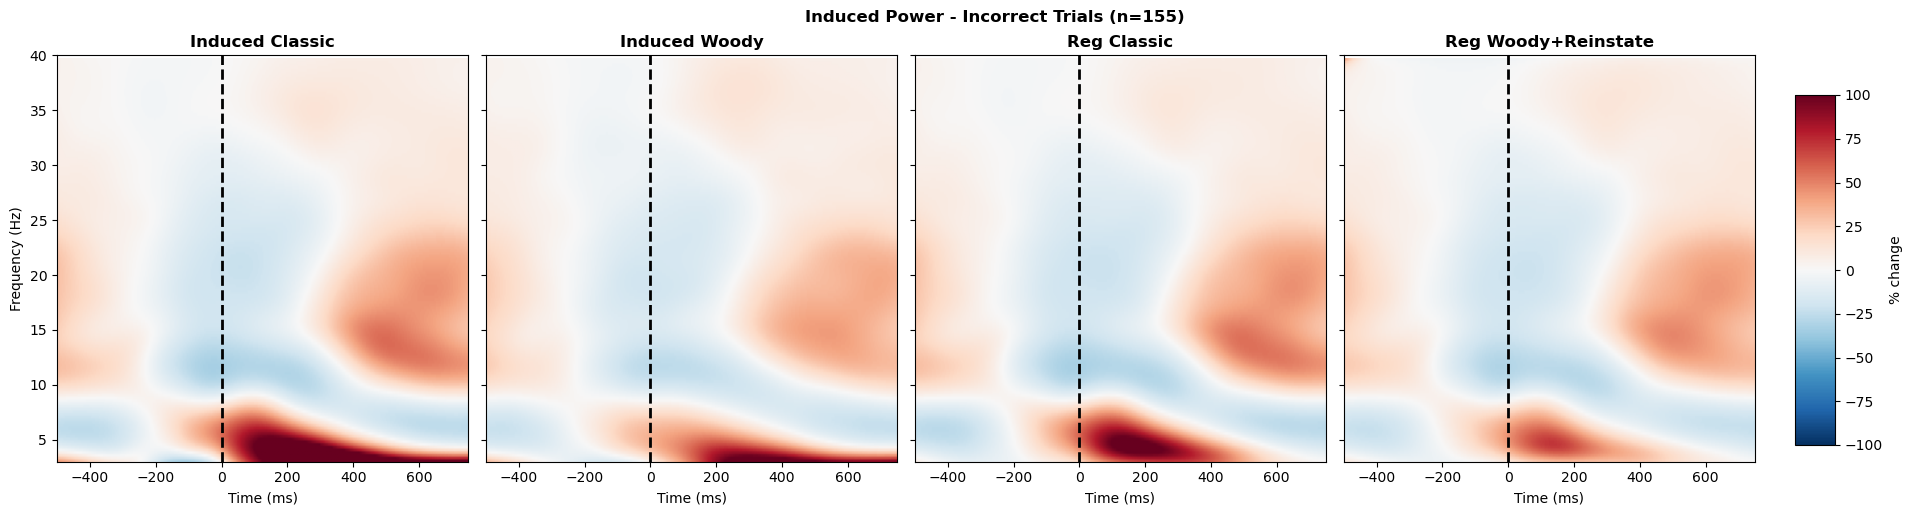

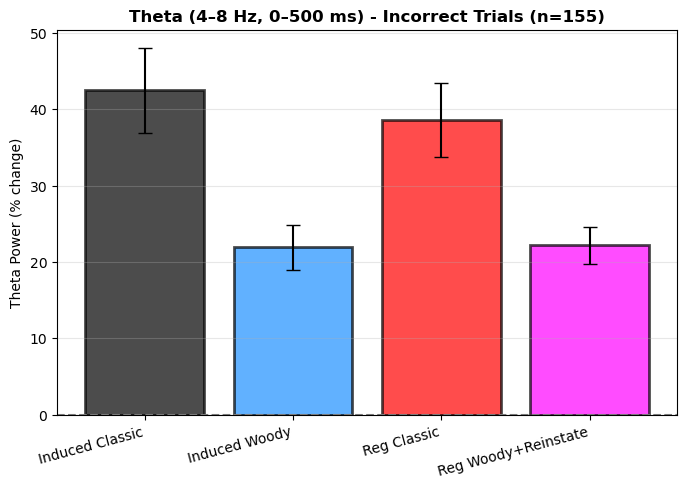

In [ ]:
plot_group_results(results_incorrect, df_incorrect, 'Incorrect Trials')

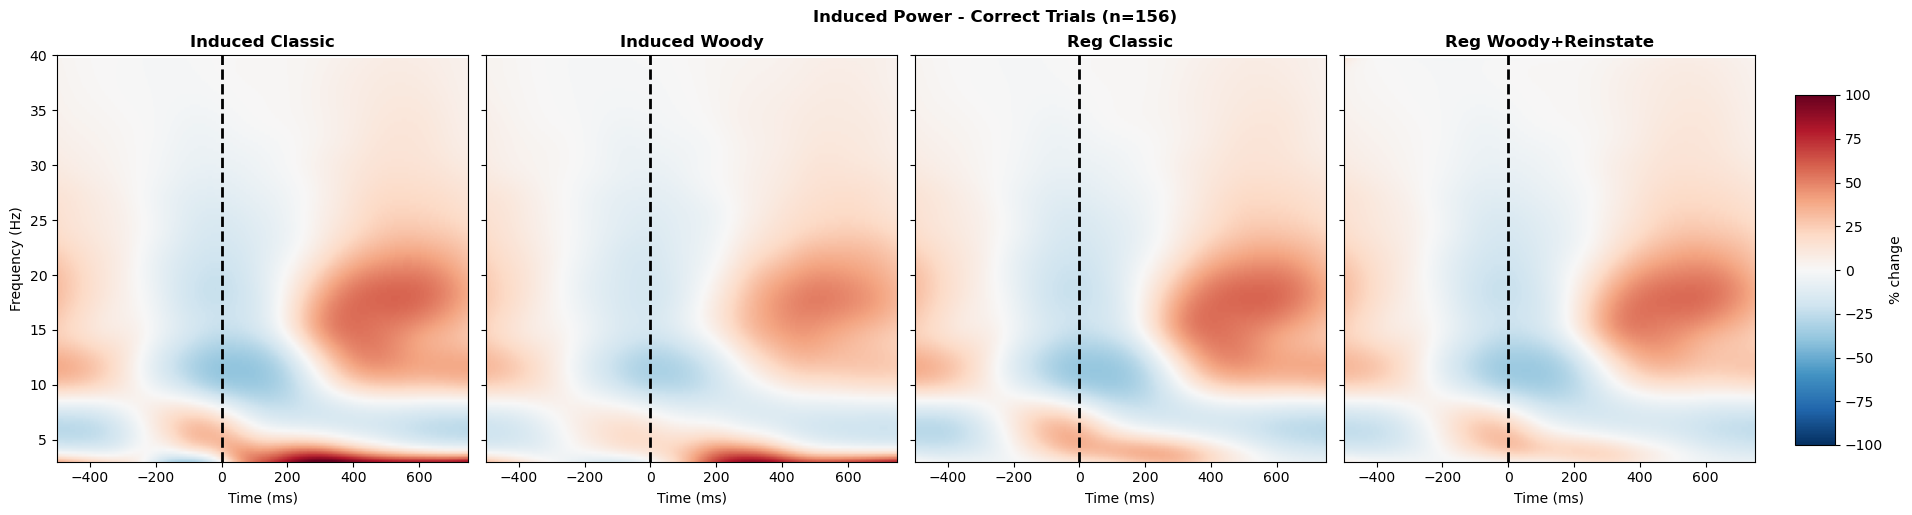

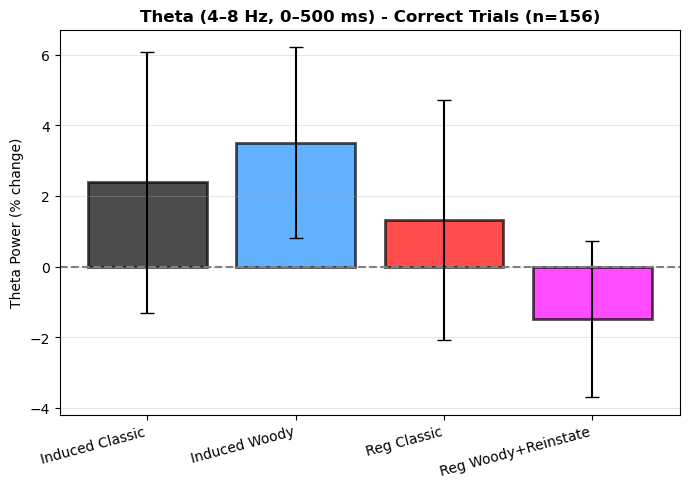

In [ ]:
plot_group_results(results_correct, df_correct, 'Correct Trials')

## Poster figure: ERP regression with and without Woody alignment

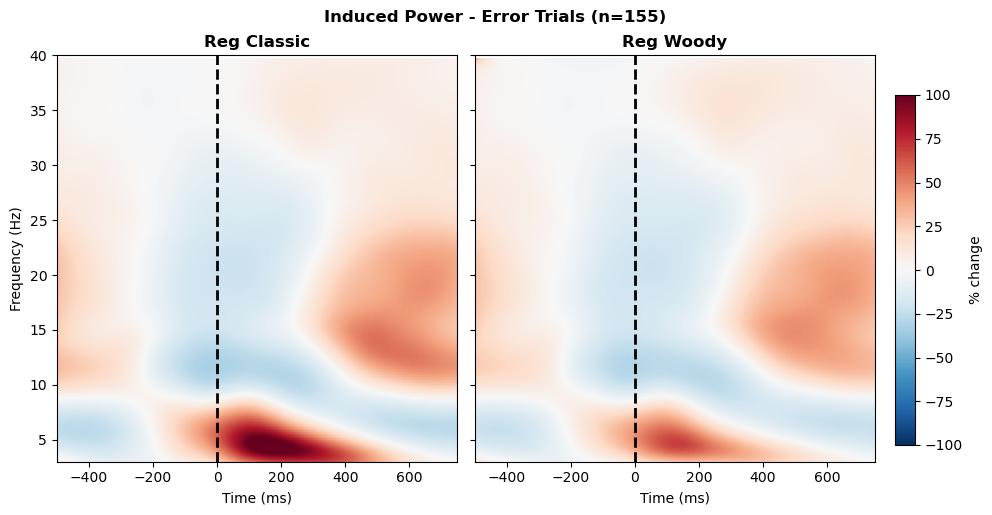

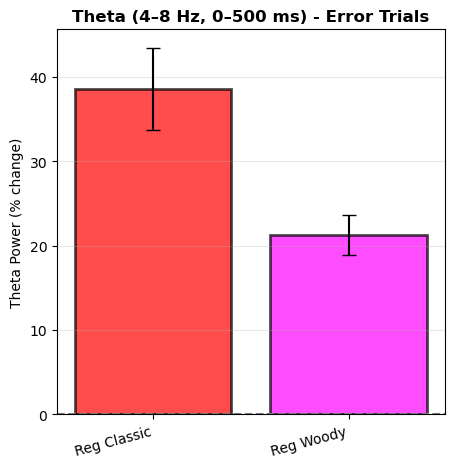

In [ ]:
POSTER_METHODS = ('Reg Classic', 'Reg Woody+Reinstate')
plot_group_results(results_incorrect, df_incorrect, 'Error Trials', POSTER_METHODS)

In [ ]:
plot_group_results(results_correct, df_correct, 'Correct Trials', POSTER_METHODS)

In [ ]:
# Theta summary (mean ± SEM, % change from baseline)
for name, df in [('Incorrect', df_incorrect), ('Correct', df_correct)]:
    print(f'{name} (n={len(df)})')
    for method in METHODS:
        print(f'  {method:<22} {df[method].mean():6.1f} ± {df[method].sem():.1f} %')

reg, reg_woody = df_incorrect['Reg Classic'], df_incorrect['Reg Woody+Reinstate']
print(f'\nError trials: Woody alignment reduces residual theta by '
      f'{(1 - reg_woody.mean() / reg.mean()) * 100:.0f}% (ratio of group means)')

## Incorrect vs correct

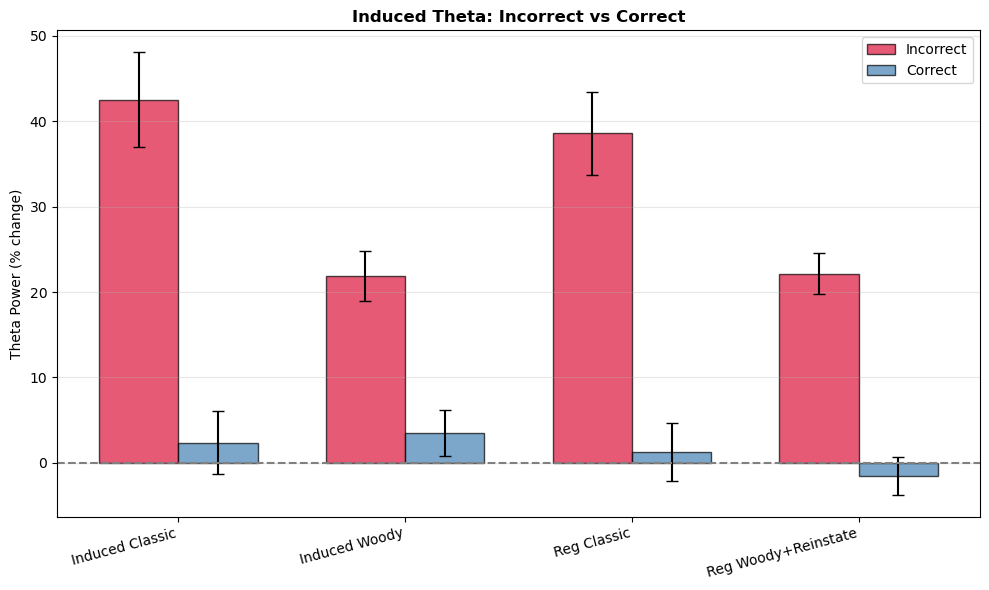

In [ ]:
methods = list(METHODS)
x, width = np.arange(len(methods)), 0.35

fig, ax = plt.subplots(figsize=(10, 6))
for offset, df, label, color in [(-width / 2, df_incorrect, 'Incorrect', 'crimson'),
                                 (width / 2, df_correct, 'Correct', 'steelblue')]:
    ax.bar(x + offset, df[methods].mean(), width, yerr=df[methods].sem(), label=label,
           color=color, alpha=0.7, edgecolor='k', capsize=4)
ax.set_xticks(x)
ax.set_xticklabels(methods, rotation=15, ha='right')
ax.axhline(0, color='gray', ls='--')
ax.set_ylabel('Theta power (% change)')
ax.set_title('Induced theta: incorrect vs correct', fontweight='bold')
ax.legend()
ax.grid(alpha=0.3, axis='y')
plt.tight_layout()

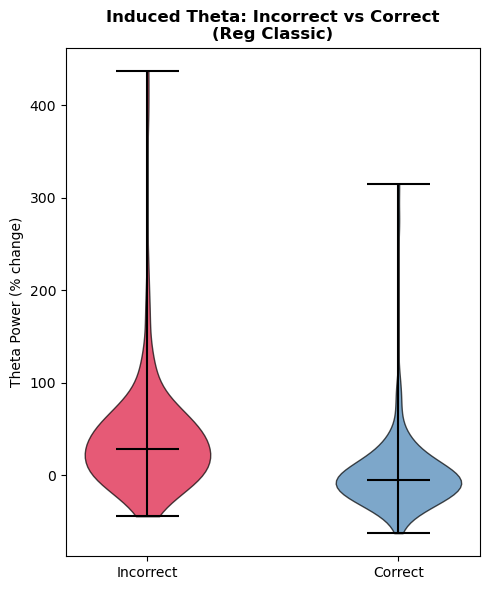

In [ ]:
fig, ax = plt.subplots(figsize=(5, 6))
parts = ax.violinplot([df_incorrect['Reg Classic'].dropna(), df_correct['Reg Classic'].dropna()],
                      positions=[1, 2], showmedians=True, showextrema=True)
for body, color in zip(parts['bodies'], ['crimson', 'steelblue']):
    body.set_facecolor(color)
    body.set_alpha(0.7)
    body.set_edgecolor('k')
for part in ('cbars', 'cmins', 'cmaxes', 'cmedians'):
    parts[part].set_edgecolor('black')
    parts[part].set_linewidth(1.5)
ax.set_xticks([1, 2])
ax.set_xticklabels(['Incorrect', 'Correct'])
ax.set_ylabel('Theta power (% change)')
ax.set_title('Induced theta: incorrect vs correct\n(Reg Classic)', fontweight='bold')
plt.tight_layout()

In [ ]:
RESULTS_DIR.mkdir(exist_ok=True)
df_incorrect.to_csv(RESULTS_DIR / 'theta_error_incorrect.csv', index=False)
df_correct.to_csv(RESULTS_DIR / 'theta_error_correct.csv', index=False)